# African Wildlife Object Detection — YOLOv8s + CBAM Attention

**Course:** CS190-4P
**Task:** Multi-class object detection (buffalo, elephant, rhino, zebra)
**Base model:** YOLOv8s (Ultralytics, pretrained on COCO)
**Attention module:** CBAM (Convolutional Block Attention Module) — channel + spatial attention, inserted into the detection neck before each of the three detection heads (P3/P4/P5)
**Dataset:** African Wildlife Dataset (Kaggle, biancaferreira) — stored in Google Drive at:

```
/content/drive/MyDrive/CS190-4P/YOLO/buffalo/
/content/drive/MyDrive/CS190-4P/YOLO/elephant/
/content/drive/MyDrive/CS190-4P/YOLO/rhino/
/content/drive/MyDrive/CS190-4P/YOLO/zebra/
```

Each folder contains `.jpg` images. This notebook auto-detects whether YOLO-format `.txt` labels sit alongside the images in the same folder or in a sibling `labels/` folder, and builds a unified, stratified train/val/test split from there.

**Pipeline covered in this notebook:**
1. Environment setup
2. Data audit (verify image/label pairing, box validity)
3. Preprocessing — unify folder structure, stratified split, `data.yaml`
4. Augmentation pipeline + visualization
5. Model definition — YOLOv8s backbone + CBAM attention in the neck
6. Sanity check (dummy forward pass before committing GPU time to training)
7. Training
8. Evaluation — per-class metrics table, confusion matrix, PR curve, F1-confidence curve, qualitative predictions, inference speed
9. Export of weights + plots back to Drive


## 1. Environment Setup

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Install Ultralytics (YOLOv8) and supporting libraries
%pip install ultralytics==8.3.* -q
%pip install seaborn -q

import ultralytics
ultralytics.checks()

Ultralytics 8.3.253 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 46.7/112.6 GB disk)


In [3]:
import os
import glob
import shutil
import random
import yaml
import json
import time
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns

import torch
import torch.nn as nn

from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---- Paths ----
DRIVE_ROOT   = '/content/drive/MyDrive/CS190-4P/YOLO'
CLASSES      = ['buffalo', 'elephant', 'rhino', 'zebra']       # index = class id, fixed convention used throughout
WORK_DIR     = '/content/wildlife_yolo'                        # local (fast) scratch space for the unified dataset
DATASET_DIR  = os.path.join(WORK_DIR, 'dataset')
RUNS_DIR     = os.path.join(WORK_DIR, 'runs')
EXPORT_DIR   = os.path.join(DRIVE_ROOT, '_experiment_outputs')  # everything we produce gets copied back here

os.makedirs(WORK_DIR, exist_ok=True)
os.makedirs(EXPORT_DIR, exist_ok=True)

print('Drive root       :', DRIVE_ROOT)
print('Classes           :', CLASSES)
print('Local working dir :', WORK_DIR)
print('Export back to    :', EXPORT_DIR)

Drive root       : /content/drive/MyDrive/CS190-4P/YOLO
Classes           : ['buffalo', 'elephant', 'rhino', 'zebra']
Local working dir : /content/wildlife_yolo
Export back to    : /content/drive/MyDrive/CS190-4P/YOLO/_experiment_outputs


## 2. Data Audit

Before touching anything, we scan every class folder and answer three questions:

- How many images does each class actually have?
- Where are the matching YOLO `.txt` label files — same folder as the image, or a sibling `labels/` folder?
- Are there any images missing a label file, or labels with malformed / out-of-range bounding boxes?

This matters because silently training on mismatched or corrupt labels is the single most common source of a YOLO model quietly under-performing.


In [4]:
def find_label_for_image(img_path, class_dir):
    """Locate the YOLO .txt label for a given image, checking the common
    layout variants: same folder, or a sibling 'labels' folder mirroring
    the image's sub-path inside an 'images' folder."""
    stem = Path(img_path).stem
    candidates = [
        Path(img_path).with_suffix('.txt'),                                   # same folder, same name
        Path(class_dir) / 'labels' / f'{stem}.txt',                           # sibling labels/ folder
        Path(str(Path(img_path).parent).replace('images', 'labels')) / f'{stem}.txt',
    ]
    for c in candidates:
        if c.exists():
            return c
    return None


def audit_class_folder(class_name):
    class_dir = os.path.join(DRIVE_ROOT, class_name)
    img_paths = sorted(glob.glob(os.path.join(class_dir, '**', '*.jpg'), recursive=True) +
                        glob.glob(os.path.join(class_dir, '**', '*.jpeg'), recursive=True) +
                        glob.glob(os.path.join(class_dir, '**', '*.JPG'), recursive=True))

    n_images, n_with_label, n_missing_label, n_bad_box, n_instances = len(img_paths), 0, 0, 0, 0
    bad_examples = []

    for img_path in img_paths:
        label_path = find_label_for_image(img_path, class_dir)
        if label_path is None:
            n_missing_label += 1
            continue
        n_with_label += 1
        with open(label_path, 'r') as f:
            lines = [l.strip() for l in f.readlines() if l.strip()]
        for line in lines:
            parts = line.split()
            if len(parts) != 5:
                n_bad_box += 1
                bad_examples.append((label_path, line, 'wrong field count'))
                continue
            cls_id, xc, yc, w, h = parts
            vals = [float(xc), float(yc), float(w), float(h)]
            if not all(0.0 <= v <= 1.0 for v in vals) or float(w) <= 0 or float(h) <= 0:
                n_bad_box += 1
                bad_examples.append((label_path, line, 'out-of-range / non-positive box'))
            else:
                n_instances += 1

    return {
        'class': class_name,
        'n_images': n_images,
        'n_with_label': n_with_label,
        'n_missing_label': n_missing_label,
        'n_instances (valid boxes)': n_instances,
        'n_bad_boxes': n_bad_box,
    }, bad_examples


audit_rows, all_bad_examples = [], []
for c in CLASSES:
    row, bad = audit_class_folder(c)
    audit_rows.append(row)
    all_bad_examples.extend(bad)

audit_df = pd.DataFrame(audit_rows)
audit_df.loc['TOTAL'] = audit_df.sum(numeric_only=True)
audit_df.loc['TOTAL', 'class'] = 'TOTAL'
print('=== Dataset Audit ===')
display(audit_df)

if all_bad_examples:
    print(f'\nFound {len(all_bad_examples)} malformed label lines. First 5 shown:')
    for ex in all_bad_examples[:5]:
        print(ex)
else:
    print('\nNo malformed bounding boxes detected.')

assert audit_df.loc['TOTAL', 'n_missing_label'] == 0, 'Some images are missing label files -- check DRIVE_ROOT folder layout before continuing.'

=== Dataset Audit ===


,class,n_images,n_with_label,n_missing_label,n_instances (valid boxes),n_bad_boxes
0,buffalo,376.0,376.0,0.0,563.0,0.0
1,elephant,376.0,376.0,0.0,752.0,0.0
2,rhino,376.0,376.0,0.0,568.0,0.0
3,zebra,376.0,376.0,0.0,802.0,0.0
TOTAL,TOTAL,1504.0,1504.0,0.0,2685.0,0.0



No malformed bounding boxes detected.


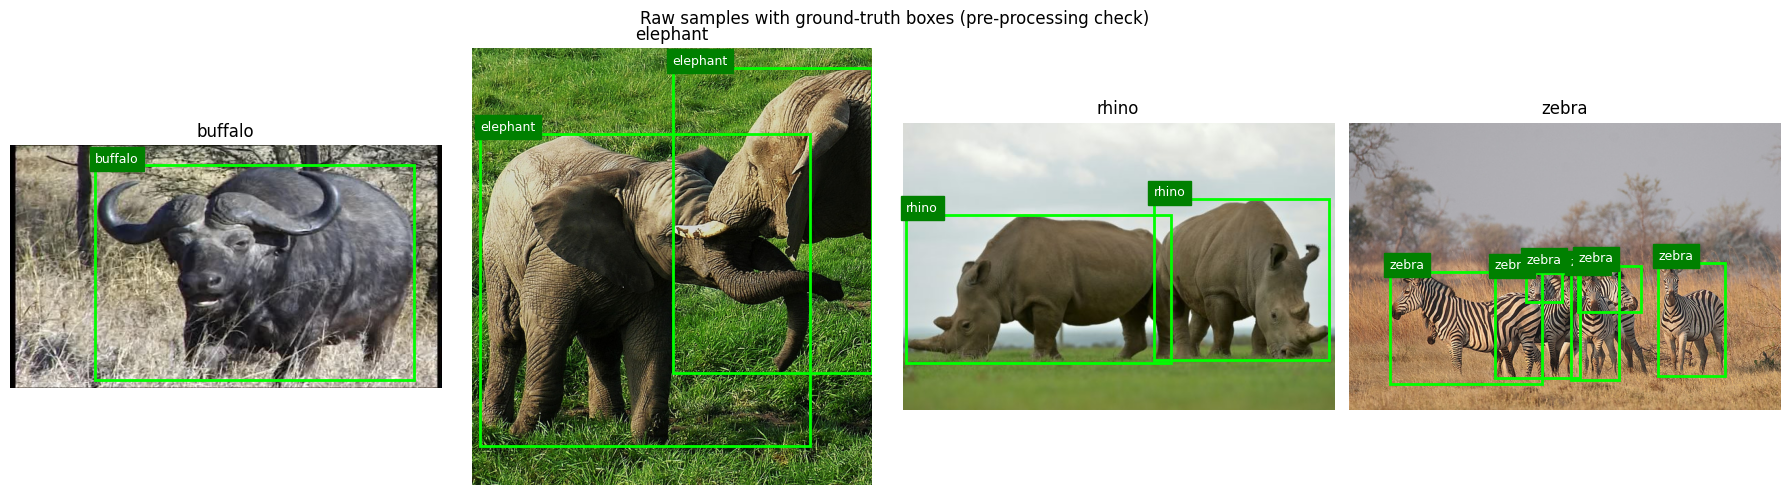

In [5]:
# Visual sanity check: plot a few raw images with their ground-truth boxes,
# straight from the Drive folders, before any preprocessing happens.
def draw_yolo_boxes(ax, img, label_path, class_names):
    h, w = img.shape[:2]
    with open(label_path) as f:
        for line in f:
            parts = line.split()
            if len(parts) != 5:
                continue
            cid, xc, yc, bw, bh = int(parts[0]), *map(float, parts[1:])
            x1 = (xc - bw / 2) * w
            y1 = (yc - bh / 2) * h
            rect = patches.Rectangle((x1, y1), bw * w, bh * h, linewidth=2,
                                      edgecolor='lime', facecolor='none')
            ax.add_patch(rect)
            ax.text(x1, max(y1 - 5, 0), class_names[cid], color='white',
                     fontsize=9, backgroundcolor='green')

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, class_name in zip(axes, CLASSES):
    class_dir = os.path.join(DRIVE_ROOT, class_name)
    img_paths = sorted(glob.glob(os.path.join(class_dir, '**', '*.jpg'), recursive=True))
    img_path = random.choice(img_paths)
    label_path = find_label_for_image(img_path, class_dir)
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    draw_yolo_boxes(ax, img, label_path, CLASSES)
    ax.set_title(class_name)
    ax.axis('off')
plt.suptitle('Raw samples with ground-truth boxes (pre-processing check)')
plt.tight_layout()
plt.show()

## 3. Preprocessing — Unified Structure + Stratified Split

We now:
1. Copy every (image, label) pair into a single local working directory (local disk is much faster than reading from Drive during training).
2. Split **per class** into train / val / test (70% / 15% / 15%) so each split preserves the original class balance — this is a stratified split, not a random shuffle of the whole pool.
3. Re-index label class IDs to the fixed convention `{0: buffalo, 1: elephant, 2: rhino, 3: zebra}`, since some raw label files can use per-folder-local class IDs.
4. Emit `data.yaml` for Ultralytics.


In [6]:
SPLITS = {'train': 0.70, 'val': 0.15, 'test': 0.15}
assert abs(sum(SPLITS.values()) - 1.0) < 1e-9

for split in SPLITS:
    os.makedirs(os.path.join(DATASET_DIR, 'images', split), exist_ok=True)
    os.makedirs(os.path.join(DATASET_DIR, 'labels', split), exist_ok=True)

split_manifest = defaultdict(lambda: defaultdict(int))  # split -> class -> n_images

for class_idx, class_name in enumerate(CLASSES):
    class_dir = os.path.join(DRIVE_ROOT, class_name)
    img_paths = sorted(glob.glob(os.path.join(class_dir, '**', '*.jpg'), recursive=True) +
                        glob.glob(os.path.join(class_dir, '**', '*.jpeg'), recursive=True))
    random.Random(SEED).shuffle(img_paths)

    n = len(img_paths)
    n_train = int(round(n * SPLITS['train']))
    n_val = int(round(n * SPLITS['val']))
    split_assignment = (['train'] * n_train + ['val'] * n_val +
                         ['test'] * (n - n_train - n_val))

    for img_path, split in zip(img_paths, split_assignment):
        label_path = find_label_for_image(img_path, class_dir)
        stem = f'{class_name}_{Path(img_path).stem}'  # prefix avoids filename collisions across classes

        dst_img = os.path.join(DATASET_DIR, 'images', split, stem + Path(img_path).suffix.lower())
        dst_lbl = os.path.join(DATASET_DIR, 'labels', split, stem + '.txt')
        shutil.copy2(img_path, dst_img)

        # Re-write label lines, forcing the class id to our fixed CLASSES index
        with open(label_path) as f_in, open(dst_lbl, 'w') as f_out:
            for line in f_in:
                parts = line.split()
                if len(parts) != 5:
                    continue
                _, xc, yc, bw, bh = parts
                f_out.write(f'{class_idx} {xc} {yc} {bw} {bh}\n')

        split_manifest[split][class_name] += 1

manifest_df = pd.DataFrame(split_manifest).fillna(0).astype(int).T
manifest_df['total'] = manifest_df.sum(axis=1)
manifest_df.loc['total'] = manifest_df.sum(axis=0)
print('=== Final Split Manifest (image counts) ===')
display(manifest_df)

=== Final Split Manifest (image counts) ===


,buffalo,elephant,rhino,zebra,total
train,262,262,262,263,1049
val,56,56,56,56,224
test,57,57,57,57,228
total,375,375,375,376,1501


In [7]:
# data.yaml for Ultralytics
data_yaml = {
    'path': DATASET_DIR,
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {i: c for i, c in enumerate(CLASSES)},
}
data_yaml_path = os.path.join(WORK_DIR, 'data.yaml')
with open(data_yaml_path, 'w') as f:
    yaml.dump(data_yaml, f, sort_keys=False)

print(open(data_yaml_path).read())

path: /content/wildlife_yolo/dataset
train: images/train
val: images/val
test: images/test
names:
  0: buffalo
  1: elephant
  2: rhino
  3: zebra



## 4. Preprocessing Transforms & Augmentation

Two things are happening to the data before it reaches the network:

- **Deterministic pre-processing** (always applied, train/val/test alike): letterbox resize to 640x640 (preserves aspect ratio, pads with grey) and pixel normalization to `[0, 1]`.
- **Stochastic augmentation** (train split only): mosaic (4-image composite), horizontal flip, HSV color jitter, random scale/translate. These are Ultralytics' built-in, well-documented augmentations and are configured explicitly as hyperparameters in the training call in Section 6, not hidden defaults.

The cell below renders a manual before/after preview so the effect is visible before we commit to a full training run.


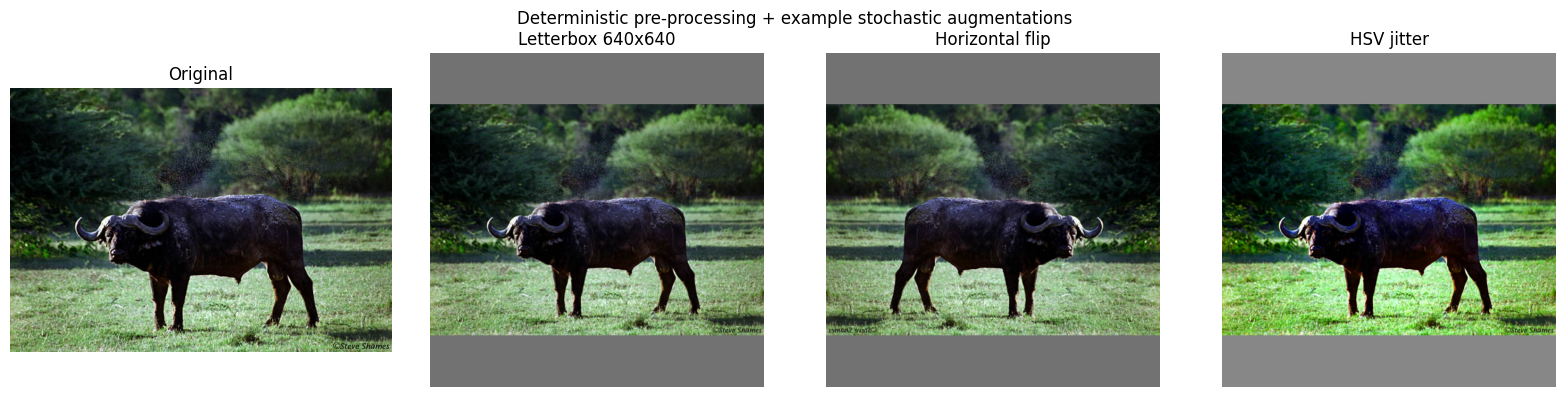

Pixel range after normalization: min=0.000 max=1.000
Note: mosaic augmentation (4-image composite) is applied internally by the Ultralytics
dataloader during training and is configured via the mosaic hyperparameter in Section 6.


In [8]:
def letterbox(img, new_shape=640, color=(114, 114, 114)):
    h, w = img.shape[:2]
    r = min(new_shape / h, new_shape / w)
    new_unpad = (int(round(w * r)), int(round(h * r)))
    dw, dh = new_shape - new_unpad[0], new_shape - new_unpad[1]
    dw, dh = dw / 2, dh / 2
    resized = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    return cv2.copyMakeBorder(resized, top, bottom, left, right, cv2.BORDER_CONSTANT, value=color)


def hsv_jitter(img, h_gain=0.015, s_gain=0.7, v_gain=0.4):
    img_hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    r = np.random.uniform(-1, 1, 3) * [h_gain, s_gain, v_gain] + 1
    img_hsv[..., 0] = (img_hsv[..., 0] * r[0]) % 180
    img_hsv[..., 1] = np.clip(img_hsv[..., 1] * r[1], 0, 255)
    img_hsv[..., 2] = np.clip(img_hsv[..., 2] * r[2], 0, 255)
    return cv2.cvtColor(img_hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)


sample_img_path = glob.glob(os.path.join(DATASET_DIR, 'images', 'train', '*'))[0]
orig = cv2.cvtColor(cv2.imread(sample_img_path), cv2.COLOR_BGR2RGB)

lb = letterbox(orig, 640)
flipped = cv2.flip(lb, 1)
jittered = hsv_jitter(lb)
norm = (lb / 255.0)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titles = ['Original', 'Letterbox 640x640', 'Horizontal flip', 'HSV jitter']
imgs = [orig, lb, flipped, jittered]
for ax, im, t in zip(axes, imgs, titles):
    ax.imshow(im)
    ax.set_title(t)
    ax.axis('off')
plt.suptitle('Deterministic pre-processing + example stochastic augmentations')
plt.tight_layout()
plt.show()

print('Pixel range after normalization: min=%.3f max=%.3f' % (norm.min(), norm.max()))
print('Note: mosaic augmentation (4-image composite) is applied internally by the Ultralytics')
print('dataloader during training and is configured via the mosaic hyperparameter in Section 6.')

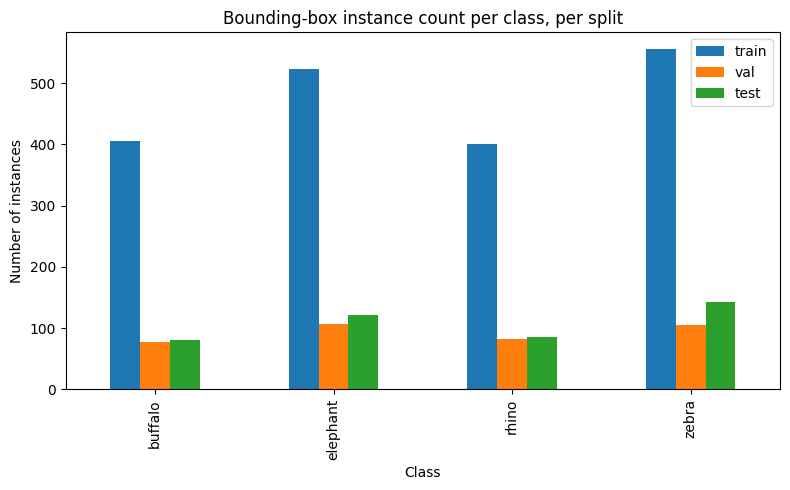

,train,val,test
buffalo,405,77,80
elephant,523,107,121
rhino,400,82,85
zebra,555,105,142


In [9]:
# Class instance distribution across splits (counts bounding boxes, not just images)
def count_instances(split):
    counts = Counter()
    for lbl_path in glob.glob(os.path.join(DATASET_DIR, 'labels', split, '*.txt')):
        with open(lbl_path) as f:
            for line in f:
                cid = int(line.split()[0])
                counts[CLASSES[cid]] += 1
    return counts

inst_df = pd.DataFrame({split: count_instances(split) for split in SPLITS}).fillna(0).astype(int)
inst_df = inst_df.reindex(CLASSES)

ax = inst_df.plot(kind='bar', figsize=(8, 5))
ax.set_title('Bounding-box instance count per class, per split')
ax.set_xlabel('Class')
ax.set_ylabel('Number of instances')
plt.tight_layout()
plt.show()

display(inst_df)

## 5. Model — YOLOv8s Backbone + CBAM Attention

We keep the standard YOLOv8s backbone (CSPDarknet-style, pretrained on COCO) untouched, and modify the **neck**: a CBAM block is inserted after each of the three output stages (P3/8-small, P4/16-medium, P5/32-large), immediately before the features are handed to the detection head. This lets the model re-weight *which channels* and *which spatial regions* matter most for each scale, right before the final classification/regression — a natural place to help with a dataset where animals can be partially occluded by vegetation or vary a lot in scale (rhino vs. small distant zebra).

**CBAM** = Channel Attention (squeeze-excite-style, using both avg- and max-pooled context) followed by Spatial Attention (a 7x7 conv over channel-pooled feature maps). It adds a negligible number of parameters relative to the backbone.

Technical note: Ultralytics' model parser (`parse_model`) only auto-scales channel counts for its own recognized module types. Custom modules fall through to a default branch that preserves the input channel count (`c2 = ch[f]`), which is exactly the behavior we want for an attention block — but it means the CBAM layer needs to be told its channel count explicitly in the YAML rather than inferring it. The values below (128 / 256 / 512) are the true post-scaling channel counts for the **YOLOv8s** width multiplier specifically — if you ever swap to n/m/l/x you must recompute these.


In [10]:
# ---- CBAM module ----
class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, 1, bias=False),
        )

    def forward(self, x):
        avg_out = self.mlp(torch.nn.functional.adaptive_avg_pool2d(x, 1))
        max_out = self.mlp(torch.nn.functional.adaptive_max_pool2d(x, 1))
        return x * torch.sigmoid(avg_out + max_out)


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        y = torch.cat([avg_out, max_out], dim=1)
        return x * torch.sigmoid(self.conv(y))


class CBAM(nn.Module):
    """Convolutional Block Attention Module (Woo et al., 2018).
    channels : input/output channel count (unchanged by this block)
    reduction: bottleneck reduction ratio for the channel-attention MLP
    kernel_size: spatial-attention conv kernel size
    """
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()
        self.channel_attention = ChannelAttention(channels, reduction)
        self.spatial_attention = SpatialAttention(kernel_size)

    def forward(self, x):
        x = self.channel_attention(x)
        x = self.spatial_attention(x)
        return x


# Register CBAM so Ultralytics' YAML parser can resolve the string "CBAM" to this class.
# parse_model() resolves module names via the global namespace of ultralytics.nn.tasks,
# so we inject our class into that module's namespace at runtime (no source files edited).
import ultralytics.nn.tasks as ul_tasks
ul_tasks.CBAM = CBAM
print('CBAM registered in ultralytics.nn.tasks namespace:', hasattr(ul_tasks, 'CBAM'))

CBAM registered in ultralytics.nn.tasks namespace: True


In [11]:
# ---- Custom model YAML: YOLOv8s backbone, CBAM-augmented neck ----
yolov8s_cbam_yaml = """
# YOLOv8s backbone + CBAM attention in the neck (custom, built for the African Wildlife project)
nc: 4
scales:
  s: [0.33, 0.50, 1024]   # depth_multiple, width_multiple, max_channels

backbone:
  - [-1, 1, Conv, [64, 3, 2]]        # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]]       # 1-P2/4
  - [-1, 3, C2f, [128, True]]        # 2
  - [-1, 1, Conv, [256, 3, 2]]       # 3-P3/8
  - [-1, 6, C2f, [256, True]]        # 4
  - [-1, 1, Conv, [512, 3, 2]]       # 5-P4/16
  - [-1, 6, C2f, [512, True]]        # 6
  - [-1, 1, Conv, [1024, 3, 2]]      # 7-P5/32
  - [-1, 3, C2f, [1024, True]]       # 8
  - [-1, 1, SPPF, [1024, 5]]         # 9

head:
  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]     # 10
  - [[-1, 6], 1, Concat, [1]]                       # 11 cat backbone P4
  - [-1, 3, C2f, [512]]                             # 12

  - [-1, 1, nn.Upsample, [None, 2, 'nearest']]     # 13
  - [[-1, 4], 1, Concat, [1]]                       # 14 cat backbone P3
  - [-1, 3, C2f, [256]]                             # 15 (P3/8-small)
  - [-1, 1, CBAM, [128, 16, 7]]                     # 16 CBAM on P3 output

  - [-1, 1, Conv, [256, 3, 2]]                      # 17
  - [[-1, 12], 1, Concat, [1]]                      # 18 cat head P4
  - [-1, 3, C2f, [512]]                             # 19 (P4/16-medium)
  - [-1, 1, CBAM, [256, 16, 7]]                     # 20 CBAM on P4 output

  - [-1, 1, Conv, [512, 3, 2]]                      # 21
  - [[-1, 9], 1, Concat, [1]]                       # 22 cat head P5
  - [-1, 3, C2f, [1024]]                            # 23 (P5/32-large)
  - [-1, 1, CBAM, [512, 16, 7]]                     # 24 CBAM on P5 output

  - [[16, 20, 24], 1, Detect, [nc]]                 # 25 Detect(P3, P4, P5) -- now fed by CBAM outputs
"""

model_yaml_path = os.path.join(WORK_DIR, 'yolov8s-cbam.yaml')
with open(model_yaml_path, 'w') as f:
    f.write(yolov8s_cbam_yaml)

print(f'Custom architecture written to: {model_yaml_path}')

Custom architecture written to: /content/wildlife_yolo/yolov8s-cbam.yaml


In [12]:
# Build the model from our custom YAML, then load COCO-pretrained weights for every
# layer whose shape matches (backbone + most of the neck) -- this is standard transfer
# learning; only the brand-new CBAM layers and the final Detect layer (different nc)
# start from random initialization.
model = YOLO(model_yaml_path)
model.load('yolov8s.pt')   # transfers matching pretrained weights by name/shape

model.info(detailed=False)

Transferred 210/364 items from pretrained weights
YOLOv8s-cbam summary: 141 layers, 11,180,450 parameters, 11,180,434 gradients, 28.7 GFLOPs


(141, 11180450, 11180434, 28.723873599999997)

### Sanity check before spending GPU time

We run one dummy forward pass through the model with a random tensor shaped like a real batch. This confirms every CBAM layer's hardcoded channel count actually matches the tensor it receives at that point in the graph, and that the three feature maps reaching `Detect` have the expected spatial strides (8/16/32), *before* we launch a multi-hour training run.


In [13]:
dummy = torch.zeros(1, 3, 640, 640)
model.model.eval()
with torch.no_grad():
    out = model.model(dummy)

# out is a list of 3 tensors [P3, P4, P5] (or a tuple during eval containing preds); print shapes either way
def describe(o, prefix=''):
    if isinstance(o, (list, tuple)):
        for i, x in enumerate(o):
            describe(x, prefix + f'[{i}]')
    elif torch.is_tensor(o):
        print(f'{prefix} shape={tuple(o.shape)}')

describe(out)
print('\nForward pass succeeded -- architecture is consistent, safe to proceed to training.')
model.model.train()

[0] shape=(1, 8, 8400)
[1][0] shape=(1, 68, 80, 80)
[1][1] shape=(1, 68, 40, 40)
[1][2] shape=(1, 68, 20, 20)

Forward pass succeeded -- architecture is consistent, safe to proceed to training.


DetectionModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C2f(
      (cv1): Conv(
        (conv): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(96, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=0.001, momentum=0.03, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
    

## 6. Training

Hyperparameters are logged explicitly below rather than left as implicit defaults. Key choices:

- **Base weights**: COCO-pretrained YOLOv8s (transfer learning — the dataset is small, ~1,500 images, so training from scratch would badly under-fit).
- **Image size**: 640x640 (standard YOLO input, matches pretrained weights).
- **Epochs**: 100, with `patience=20` early stopping on validation mAP@0.5:0.95.
- **Augmentation**: mosaic, horizontal flip, HSV jitter, translate/scale — all Ultralytics defaults, values shown explicitly for transparency.
- **Optimizer**: SGD with Ultralytics' default one-cycle LR schedule (`auto` optimizer resolves to SGD for this model size).


In [14]:
train_hyperparams = dict(
    data=data_yaml_path,
    epochs=100,
    patience=20,
    imgsz=640,
    batch=16,
    optimizer='auto',
    lr0=0.01,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=3.0,
    box=7.5,        # box loss gain
    cls=0.5,        # classification loss gain
    dfl=1.5,        # distribution focal loss gain
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=0.0, translate=0.1, scale=0.5, shear=0.0,
    fliplr=0.5, flipud=0.0,
    mosaic=1.0, mixup=0.0,
    seed=SEED,
    project=RUNS_DIR,
    name='yolov8s_cbam_wildlife',
    exist_ok=True,
    plots=True,          # let Ultralytics also generate its own PR/F1/confusion-matrix plots
    device=0 if torch.cuda.is_available() else 'cpu',
)

print(json.dumps(train_hyperparams, indent=2, default=str))

{
  "data": "/content/wildlife_yolo/data.yaml",
  "epochs": 100,
  "patience": 20,
  "imgsz": 640,
  "batch": 16,
  "optimizer": "auto",
  "lr0": 0.01,
  "lrf": 0.01,
  "momentum": 0.937,
  "weight_decay": 0.0005,
  "warmup_epochs": 3.0,
  "box": 7.5,
  "cls": 0.5,
  "dfl": 1.5,
  "hsv_h": 0.015,
  "hsv_s": 0.7,
  "hsv_v": 0.4,
  "degrees": 0.0,
  "translate": 0.1,
  "scale": 0.5,
  "shear": 0.0,
  "fliplr": 0.5,
  "flipud": 0.0,
  "mosaic": 1.0,
  "mixup": 0.0,
  "seed": 42,
  "project": "/content/wildlife_yolo/runs",
  "name": "yolov8s_cbam_wildlife",
  "exist_ok": true,
  "plots": true,
  "device": 0
}


In [15]:
results = model.train(**train_hyperparams)
RUN_DIR = results.save_dir
print('Training artifacts saved to:', RUN_DIR)

New https://pypi.org/project/ultralytics/8.4.104 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.253 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/wildlife_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/wildlife_yolo/yolov8s-cbam.yaml, momentum=0.937, mosaic=1.0, multi_scale=False, name=yolo

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/100      3.58G      2.469      3.004      3.882         29        640: 100% ━━━━━━━━━━━━ 66/66 2.2it/s 29.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.8it/s 3.9s
                   all        224        371    0.00298      0.412      0.112     0.0261

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/100      4.83G      1.774      2.009      3.314         74        640: 0% ──────────── 0/66  0.3s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/100      4.83G      1.677      1.893      2.854         36        640: 100% ━━━━━━━━━━━━ 66/66 2.6it/s 25.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.2it/s 3.1s
                   all        224        371      0.605       0.37      0.519      0.228

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/100      4.83G      1.542       1.89      2.587         60        640: 0% ──────────── 0/66  0.3s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


... (191 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


     99/100      4.83G     0.3169     0.2482     0.9269         14        640: 100% ━━━━━━━━━━━━ 66/66 2.9it/s 22.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.4it/s 2.9s
                   all        224        371      0.966      0.914      0.963      0.829

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    100/100      4.83G     0.2791     0.2257     0.9064         24        640: 0% ──────────── 0/66  0.4s

/usr/local/lib/python3.12/dist-packages/torch/autograd/graph.py:869: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


    100/100      4.83G     0.3121      0.244     0.9222         15        640: 100% ━━━━━━━━━━━━ 66/66 2.7it/s 24.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.8it/s 2.5s
                   all        224        371      0.955      0.914      0.961      0.833

100 epochs completed in 0.806 hours.
Optimizer stripped from /content/wildlife_yolo/runs/yolov8s_cbam_wildlife/weights/last.pt, 22.6MB
Optimizer stripped from /content/wildlife_yolo/runs/yolov8s_cbam_wildlife/weights/best.pt, 22.6MB

Validating /content/wildlife_yolo/runs/yolov8s_cbam_wildlife/weights/best.pt...
Ultralytics 8.3.253 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-cbam summary (fused): 84 layers, 11,170,434 parameters, 0 gradients, 28.5 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 1.7it/s 4.1s
                   all        224        371       0.95 

## 7. Training Curves (loss + mAP over epochs)

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
95,96,2791.28,0.32733,0.25718,0.92684,0.97244,0.91304,0.96724,0.83454,0.64554,0.42905,1.22814,0.000074,0.000074,0.000074
96,97,2819.18,0.32516,0.26077,0.92909,0.96980,0.90610,0.96369,0.83345,0.64075,0.43051,1.22457,0.000062,0.000062,0.000062
97,98,2846.76,0.31718,0.24573,0.91972,0.96901,0.90515,0.96288,0.83440,0.63580,0.43253,1.21810,0.000050,0.000050,0.000050
98,99,2873.80,0.31685,0.24815,0.92685,0.96557,0.91416,0.96348,0.82939,0.64263,0.43116,1.22960,0.000037,0.000037,0.000037
99,100,2901.29,0.31210,0.24396,0.92222,0.95521,0.91372,0.96056,0.83271,0.64131,0.42958,1.23314,0.000025,0.000025,0.000025


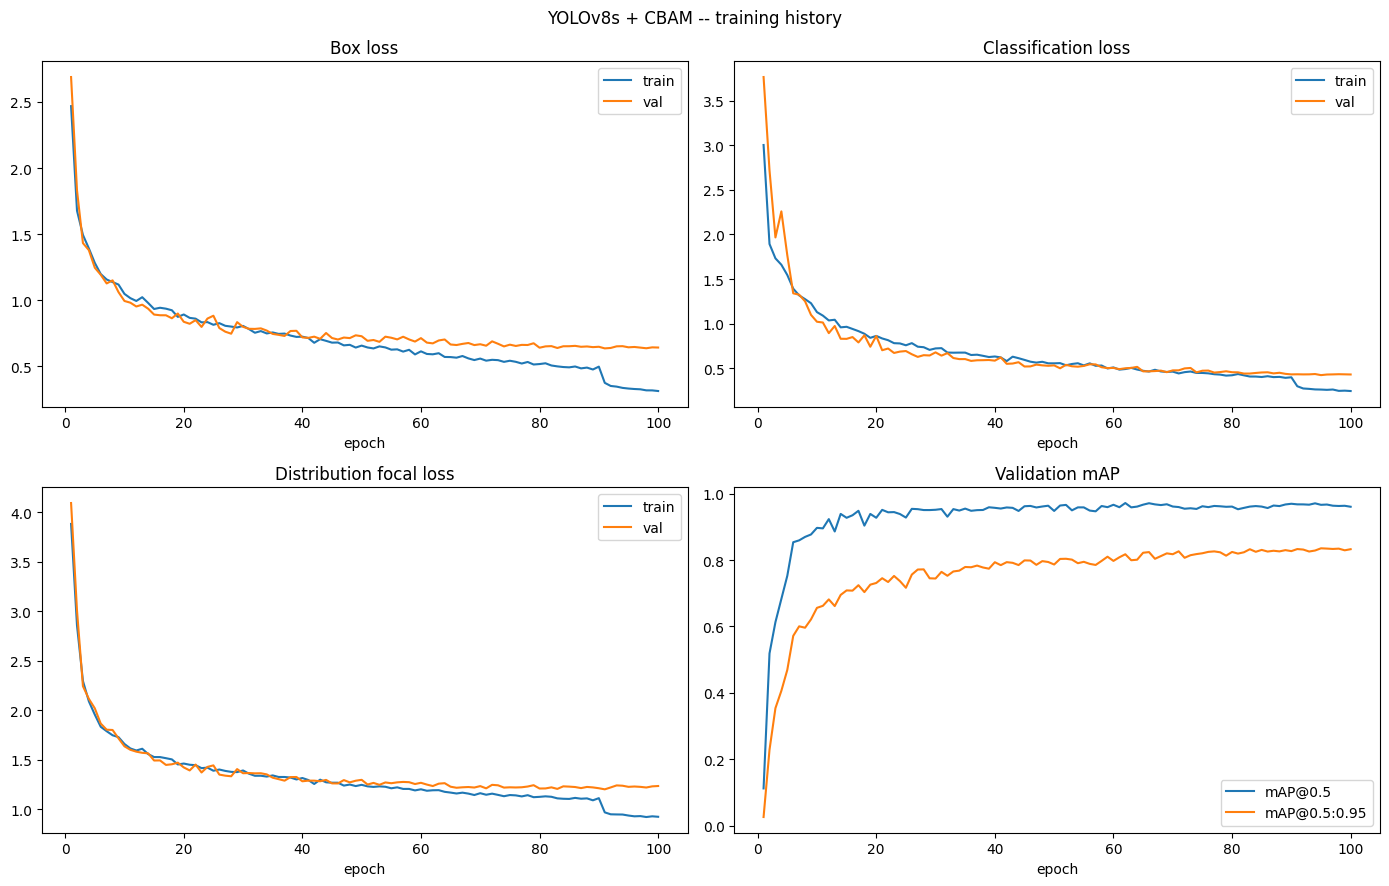

In [16]:
results_csv = os.path.join(RUN_DIR, 'results.csv')
hist = pd.read_csv(results_csv)
hist.columns = [c.strip() for c in hist.columns]
display(hist.tail())

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(hist['epoch'], hist['train/box_loss'], label='train')
axes[0, 0].plot(hist['epoch'], hist['val/box_loss'], label='val')
axes[0, 0].set_title('Box loss'); axes[0, 0].legend(); axes[0, 0].set_xlabel('epoch')

axes[0, 1].plot(hist['epoch'], hist['train/cls_loss'], label='train')
axes[0, 1].plot(hist['epoch'], hist['val/cls_loss'], label='val')
axes[0, 1].set_title('Classification loss'); axes[0, 1].legend(); axes[0, 1].set_xlabel('epoch')

axes[1, 0].plot(hist['epoch'], hist['train/dfl_loss'], label='train')
axes[1, 0].plot(hist['epoch'], hist['val/dfl_loss'], label='val')
axes[1, 0].set_title('Distribution focal loss'); axes[1, 0].legend(); axes[1, 0].set_xlabel('epoch')

axes[1, 1].plot(hist['epoch'], hist['metrics/mAP50(B)'], label='mAP@0.5')
axes[1, 1].plot(hist['epoch'], hist['metrics/mAP50-95(B)'], label='mAP@0.5:0.95')
axes[1, 1].set_title('Validation mAP'); axes[1, 1].legend(); axes[1, 1].set_xlabel('epoch')

plt.suptitle('YOLOv8s + CBAM -- training history')
plt.tight_layout()
plt.show()

## 8. Evaluation on the Held-Out Test Set

We reload the **best** checkpoint (`best.pt`, selected by Ultralytics on validation mAP during training) and run it once, cleanly, on the test split that the model has never seen in any form during training or model selection.


In [17]:
best_weights = os.path.join(RUN_DIR, 'weights', 'best.pt')
best_model = YOLO(best_weights)

test_metrics = best_model.val(data=data_yaml_path, split='test', imgsz=640, plots=True)
print('Overall (all classes):')
print(f'  Precision        : {test_metrics.box.mp:.4f}')
print(f'  Recall           : {test_metrics.box.mr:.4f}')
print(f'  mAP@0.5          : {test_metrics.box.map50:.4f}')
print(f'  mAP@0.5:0.95     : {test_metrics.box.map:.4f}')

Ultralytics 8.3.253 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv8s-cbam summary (fused): 84 layers, 11,170,434 parameters, 0 gradients, 28.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 37.8±53.6 MB/s, size: 125.1 KB)
val: Scanning /content/wildlife_yolo/dataset/labels/test... 228 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 228/228 340.0it/s 0.7s
val: New cache created: /content/wildlife_yolo/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.1it/s 4.8s
                   all        228        428      0.971      0.886      0.958      0.818
               buffalo         57         80      0.971      0.837      0.956       0.83
              elephant         57        121      0.959      0.909       0.98      0.817
                 rhino         57         85      0.988      0.976       0.99      0.899
                 zebra         57        142      

In [18]:
# Per-class metrics table
per_class_rows = []
for i, class_name in enumerate(CLASSES):
    per_class_rows.append({
        'class': class_name,
        'precision': test_metrics.box.p[i],
        'recall': test_metrics.box.r[i],
        'mAP@0.5': test_metrics.box.ap50[i],
        'mAP@0.5:0.95': test_metrics.box.ap[i],
    })
per_class_df = pd.DataFrame(per_class_rows).set_index('class').round(4)
per_class_df.loc['mean'] = per_class_df.mean()
print('=== Per-class test metrics ===')
display(per_class_df)

=== Per-class test metrics ===


,precision,recall,mAP@0.5,mAP@0.5:0.95
class,,,,
buffalo,0.971000,0.8368,0.95570,0.830400
elephant,0.958900,0.9091,0.97980,0.816700
rhino,0.988100,0.9757,0.99040,0.899000
zebra,0.966900,0.8228,0.90710,0.725600
mean,0.971225,0.8861,0.95825,0.817925


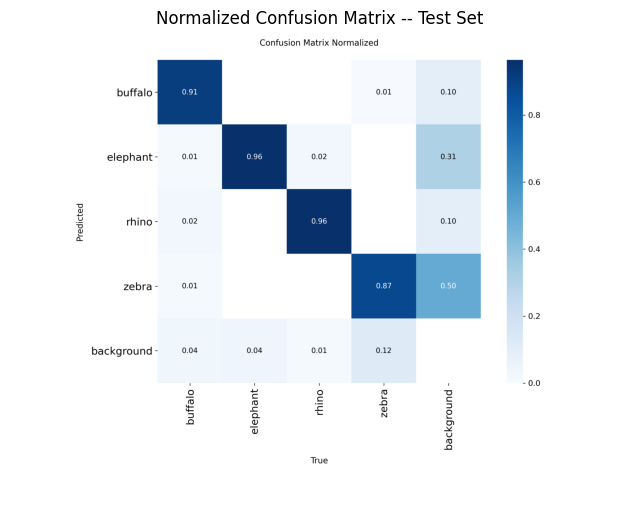

In [19]:
# Confusion matrix (Ultralytics saves this automatically during .val(); we re-display it)
test_run_dir = test_metrics.save_dir
conf_matrix_path = os.path.join(test_run_dir, 'confusion_matrix_normalized.png')
if os.path.exists(conf_matrix_path):
    img = plt.imread(conf_matrix_path)
    plt.figure(figsize=(8, 7))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Normalized Confusion Matrix -- Test Set')
    plt.show()
else:
    print('Confusion matrix image not found at expected path -- check test_run_dir contents:')
    print(os.listdir(test_run_dir))

In [20]:
# PR curve and F1-confidence curve (also auto-generated by Ultralytics' .val())
for fname, title in [('PR_curve.png', 'Precision-Recall Curve (per class + overall)'),
                      ('F1_curve.png', 'F1-Confidence Curve (per class + overall)')]:
    fpath = os.path.join(test_run_dir, fname)
    if os.path.exists(fpath):
        img = plt.imread(fpath)
        plt.figure(figsize=(8, 6))
        plt.imshow(img)
        plt.axis('off')
        plt.title(title)
        plt.show()
    else:
        print(f'{fname} not found in {test_run_dir}')

PR_curve.png not found in /content/runs/detect/val
F1_curve.png not found in /content/runs/detect/val


In [21]:
# Qualitative predictions: ground truth vs. predicted boxes, side by side, on random test images
test_img_dir = os.path.join(DATASET_DIR, 'images', 'test')
test_lbl_dir = os.path.join(DATASET_DIR, 'labels', 'test')
sample_paths = random.sample(glob.glob(os.path.join(test_img_dir, '*')), k=6)

fig, axes = plt.subplots(2, 6, figsize=(24, 8))
for col, img_path in enumerate(sample_paths):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    lbl_path = os.path.join(test_lbl_dir, Path(img_path).stem + '.txt')

    # Ground truth (top row)
    axes[0, col].imshow(img)
    draw_yolo_boxes(axes[0, col], img, lbl_path, CLASSES)
    axes[0, col].set_title('Ground truth', fontsize=9)
    axes[0, col].axis('off')

    # Prediction (bottom row)
    pred = best_model.predict(img_path, conf=0.25, verbose=False)[0]
    axes[1, col].imshow(img)
    for box in pred.boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        conf = box.conf.item()
        cid = int(box.cls.item())
        rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2,
                                  edgecolor='red', facecolor='none')
        axes[1, col].add_patch(rect)
        axes[1, col].text(x1, max(y1 - 5, 0), f'{CLASSES[cid]} {conf:.2f}',
                           color='white', fontsize=8, backgroundcolor='red')
    axes[1, col].set_title('Prediction', fontsize=9)
    axes[1, col].axis('off')

plt.suptitle('Qualitative comparison -- Ground Truth (top) vs. Prediction (bottom)')
plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [22]:
# Inference speed benchmark
n_warmup, n_bench = 5, 50
bench_img = sample_paths[0]

for _ in range(n_warmup):
    _ = best_model.predict(bench_img, verbose=False)

if torch.cuda.is_available():
    torch.cuda.synchronize()
t0 = time.time()
for _ in range(n_bench):
    _ = best_model.predict(bench_img, verbose=False)
if torch.cuda.is_available():
    torch.cuda.synchronize()
t1 = time.time()

avg_ms = (t1 - t0) / n_bench * 1000
device_used = 'GPU' if torch.cuda.is_available() else 'CPU'
print(f'Average inference time over {n_bench} runs: {avg_ms:.2f} ms/image '
      f'({1000/avg_ms:.1f} FPS) on {device_used}')

Average inference time over 50 runs: 13.88 ms/image (72.1 FPS) on GPU


In [23]:
# Summary card -- everything a reader needs at a glance
summary = {
    'model': 'YOLOv8s + CBAM (custom neck)',
    'dataset': 'African Wildlife (buffalo, elephant, rhino, zebra)',
    'train/val/test images': [len(glob.glob(os.path.join(DATASET_DIR, 'images', s, '*'))) for s in SPLITS],
    'overall_precision': float(test_metrics.box.mp),
    'overall_recall': float(test_metrics.box.mr),
    'overall_mAP50': float(test_metrics.box.map50),
    'overall_mAP50_95': float(test_metrics.box.map),
    'avg_inference_ms': float(avg_ms),
}
print(json.dumps(summary, indent=2))

{
  "model": "YOLOv8s + CBAM (custom neck)",
  "dataset": "African Wildlife (buffalo, elephant, rhino, zebra)",
  "train/val/test images": [
    1049,
    224,
    228
  ],
  "overall_precision": 0.9712063768390121,
  "overall_recall": 0.886103526579806,
  "overall_mAP50": 0.958234041273564,
  "overall_mAP50_95": 0.8179281169351962,
  "avg_inference_ms": 13.875260353088379
}



=== TRAIN -- per-class metrics ===


,precision,recall,f1_score,accuracy,TP,FP,FN
class,,,,,,,
buffalo,0.9552,1.0000,0.9771,0.9552,405,19,0
elephant,0.9685,0.9981,0.9831,0.9667,522,17,1
rhino,0.9852,1.0000,0.9926,0.9852,400,6,0
zebra,0.9635,0.9982,0.9805,0.9618,554,21,1



=== VAL -- per-class metrics ===


,precision,recall,f1_score,accuracy,TP,FP,FN
class,,,,,,,
buffalo,0.9250,0.9610,0.9427,0.8916,74,6,3
elephant,0.8829,0.9159,0.8991,0.8167,98,13,9
rhino,0.9877,0.9756,0.9816,0.9639,80,1,2
zebra,0.8750,0.9333,0.9032,0.8235,98,14,7



=== TEST -- per-class metrics ===


,precision,recall,f1_score,accuracy,TP,FP,FN
class,,,,,,,
buffalo,0.9367,0.9250,0.9308,0.8706,74,5,6
elephant,0.9070,0.9669,0.9360,0.8797,117,12,4
rhino,0.9540,0.9765,0.9651,0.9326,83,4,2
zebra,0.8723,0.8662,0.8693,0.7688,123,18,19



=== OVERALL SUMMARY: Precision / Recall / F1 / Accuracy / Avg Confidence ===


,precision,recall,f1_score,accuracy (avg),avg_confidence,n_images,n_predictions
train,0.968087,0.999072,0.983305,0.967221,0.914149,1049,1944
val,0.917634,0.946467,0.931645,0.873904,0.874701,224,384
test,0.917512,0.933652,0.925298,0.862905,0.856678,228,436


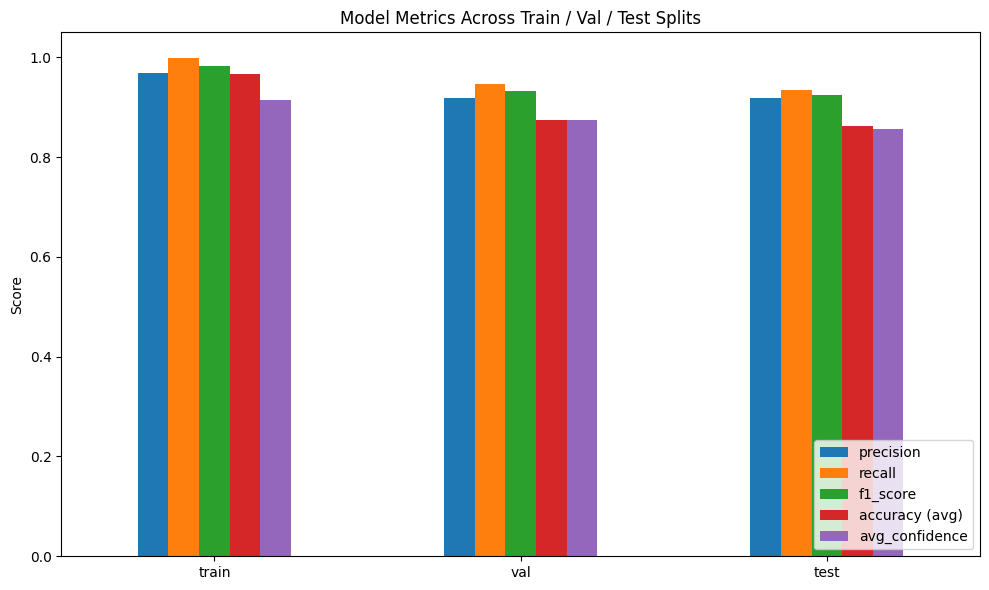


Saved metrics_summary_train_val_test.csv and per-split per-class CSVs to /content/drive/MyDrive/CS190-4P/YOLO/_experiment_outputs


In [25]:
# ============================================================
# COMPREHENSIVE METRICS: Precision, Recall, F1, Accuracy,
# Average Accuracy, Average Confidence -- Train / Val / Test
# ============================================================

import numpy as np
import pandas as pd
import glob, os
from pathlib import Path

CONF_THRES = 0.25
IOU_MATCH_THRES = 0.5

def load_gt_boxes(label_path, img_w, img_h):
    """Return list of (class_id, x1, y1, x2, y2) in pixel coords."""
    boxes = []
    if not os.path.exists(label_path):
        return boxes
    with open(label_path) as f:
        for line in f:
            parts = line.split()
            if len(parts) != 5:
                continue
            cid, xc, yc, w, h = int(parts[0]), *map(float, parts[1:])
            x1 = (xc - w / 2) * img_w
            y1 = (yc - h / 2) * img_h
            x2 = (xc + w / 2) * img_w
            y2 = (yc + h / 2) * img_h
            boxes.append((cid, x1, y1, x2, y2))
    return boxes

def iou(box_a, box_b):
    xa1, ya1, xa2, ya2 = box_a
    xb1, yb1, xb2, yb2 = box_b
    ix1, iy1 = max(xa1, xb1), max(ya1, yb1)
    ix2, iy2 = min(xa2, xb2), min(ya2, yb2)
    iw, ih = max(0, ix2 - ix1), max(0, iy2 - iy1)
    inter = iw * ih
    area_a = max(0, xa2 - xa1) * max(0, ya2 - ya1)
    area_b = max(0, xb2 - xb1) * max(0, yb2 - yb1)
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0

def evaluate_split(split, model, dataset_dir, classes, conf_thres=CONF_THRES, iou_thres=IOU_MATCH_THRES):
    img_dir = os.path.join(dataset_dir, 'images', split)
    lbl_dir = os.path.join(dataset_dir, 'labels', split)
    img_paths = sorted(glob.glob(os.path.join(img_dir, '*')))

    n_classes = len(classes)
    tp = np.zeros(n_classes, dtype=int)
    fp = np.zeros(n_classes, dtype=int)
    fn = np.zeros(n_classes, dtype=int)
    all_confidences = []

    for img_path in img_paths:
        result = model.predict(img_path, conf=conf_thres, verbose=False)[0]
        img_h, img_w = result.orig_shape

        lbl_path = os.path.join(lbl_dir, Path(img_path).stem + '.txt')
        gt_boxes = load_gt_boxes(lbl_path, img_w, img_h)
        gt_matched = [False] * len(gt_boxes)

        pred_boxes = []
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].tolist()
            conf = box.conf.item()
            cid = int(box.cls.item())
            pred_boxes.append((cid, x1, y1, x2, y2, conf))
            all_confidences.append(conf)

        # Sort predictions by confidence, descending, for greedy matching
        pred_boxes.sort(key=lambda b: b[5], reverse=True)

        for cid, x1, y1, x2, y2, conf in pred_boxes:
            best_iou, best_j = 0.0, -1
            for j, (gcid, gx1, gy1, gx2, gy2) in enumerate(gt_boxes):
                if gt_matched[j] or gcid != cid:
                    continue
                cur_iou = iou((x1, y1, x2, y2), (gx1, gy1, gx2, gy2))
                if cur_iou > best_iou:
                    best_iou, best_j = cur_iou, j
            if best_iou >= iou_thres:
                tp[cid] += 1
                gt_matched[best_j] = True
            else:
                fp[cid] += 1

        for j, (gcid, *_ ) in enumerate(gt_boxes):
            if not gt_matched[j]:
                fn[gcid] += 1

    precision = np.divide(tp, tp + fp, out=np.zeros(n_classes), where=(tp + fp) > 0)
    recall = np.divide(tp, tp + fn, out=np.zeros(n_classes), where=(tp + fn) > 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                    out=np.zeros(n_classes), where=(precision + recall) > 0)
    accuracy = np.divide(tp, tp + fp + fn, out=np.zeros(n_classes), where=(tp + fp + fn) > 0)

    per_class_df = pd.DataFrame({
        'class': classes,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'accuracy': accuracy,
        'TP': tp, 'FP': fp, 'FN': fn,
    }).set_index('class').round(4)

    overall = {
        'split': split,
        'precision': float(precision.mean()),
        'recall': float(recall.mean()),
        'f1_score': float(f1.mean()),
        'accuracy (avg)': float(accuracy.mean()),
        'avg_confidence': float(np.mean(all_confidences)) if all_confidences else 0.0,
        'n_images': len(img_paths),
        'n_predictions': len(all_confidences),
    }
    return overall, per_class_df


# ---- Run across all three splits ----
overall_rows = {}
per_class_tables = {}

for split in ['train', 'val', 'test']:
    overall, per_class_df = evaluate_split(split, best_model, DATASET_DIR, CLASSES)
    overall_rows[split] = overall
    per_class_tables[split] = per_class_df
    print(f'\n=== {split.upper()} -- per-class metrics ===')
    display(per_class_df)

summary_df = pd.DataFrame(overall_rows).T
summary_df = summary_df[['precision', 'recall', 'f1_score', 'accuracy (avg)', 'avg_confidence', 'n_images', 'n_predictions']]
summary_df = summary_df.round(4)

print('\n=== OVERALL SUMMARY: Precision / Recall / F1 / Accuracy / Avg Confidence ===')
display(summary_df)

# ---- Bar chart comparison across splits ----
plot_metrics = ['precision', 'recall', 'f1_score', 'accuracy (avg)', 'avg_confidence']
ax = summary_df[plot_metrics].plot(kind='bar', figsize=(10, 6))
ax.set_title('Model Metrics Across Train / Val / Test Splits')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# ---- Save to Drive alongside your other exported outputs ----
summary_df.to_csv(os.path.join(EXPORT_DIR, 'metrics_summary_train_val_test.csv'))
for split, df in per_class_tables.items():
    df.to_csv(os.path.join(EXPORT_DIR, f'per_class_metrics_{split}.csv'))
print('\nSaved metrics_summary_train_val_test.csv and per-split per-class CSVs to', EXPORT_DIR)

## 9. Export Weights + Plots Back to Drive

Copies the best/last weights, the full training-run folder (all auto-generated Ultralytics plots), and the metrics tables produced above into `CS190-4P/YOLO/_experiment_outputs/` so everything survives the Colab session ending.


In [26]:
export_run_dir = os.path.join(EXPORT_DIR, 'yolov8s_cbam_wildlife_run')
if os.path.exists(export_run_dir):
    shutil.rmtree(export_run_dir)
shutil.copytree(RUN_DIR, export_run_dir)

per_class_df.to_csv(os.path.join(EXPORT_DIR, 'per_class_test_metrics.csv'))
audit_df.to_csv(os.path.join(EXPORT_DIR, 'dataset_audit.csv'))
manifest_df.to_csv(os.path.join(EXPORT_DIR, 'split_manifest.csv'))
with open(os.path.join(EXPORT_DIR, 'run_summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)

print('Exported to Drive:', export_run_dir)
print('Contents:', os.listdir(export_run_dir)[:10], '...')

Exported to Drive: /content/drive/MyDrive/CS190-4P/YOLO/_experiment_outputs/yolov8s_cbam_wildlife_run
Contents: ['BoxR_curve.png', 'train_batch0.jpg', 'train_batch5940.jpg', 'train_batch1.jpg', 'confusion_matrix.png', 'labels.jpg', 'val_batch1_labels.jpg', 'val_batch2_pred.jpg', 'args.yaml', 'val_batch1_pred.jpg'] ...


### Optional: export to ONNX for deployment

Uncomment and run if you need a portable inference format (e.g. for edge deployment in a camera-trap device).


In [27]:
# best_model.export(format='onnx', imgsz=640)
# onnx_path = best_weights.replace('.pt', '.onnx')
# shutil.copy2(onnx_path, EXPORT_DIR)
# print('ONNX model exported to', EXPORT_DIR)